# MEMC exercise 5 – Mixtures and ordered samples

---

Two techniques that build new generators out of ready-made ones:

1. **Superposition (a mixture of distributions):** the density is a weighted sum of simpler
   densities. We generate in two steps: first we **pick a component** (the discrete problem from
   exercise 3), then we **draw a value** from it (exercise 4).
2. **Ordered samples:** we want $n$ uniform numbers that come out **already sorted**, and without
   sorting them. We show that this can be done in $O(n)$, and that we can even generate only the
   **largest values** out of a huge sample.

In [1]:
import math
import random
import time
from bisect import bisect_right
from itertools import accumulate

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {mean:.5f} +- {se:.5f}  (exact {exact:.5f})")
    assert abs(mean - exact) <= k * se, name


# generators from the previous exercises
def uniform(a, b):
    return a + (b - a) * random.random()


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam


def triangular(a, b, c):
    gamma = random.random()
    threshold = (c - a) / (b - a)   # F(c)
    if gamma < threshold:
        return a + math.sqrt(gamma * (b - a) * (c - a))
    return b - math.sqrt((1.0 - gamma) * (b - a) * (b - c))


def make_bisect(p):
    '''A discrete distribution with probabilities p: cumulative sums + bisection (exercise 3).'''
    cum = list(accumulate(p))
    return lambda: min(bisect_right(cum, random.random()), len(p) - 1)

## 1. Superposition (a mixture of distributions)

The density is a weighted sum of $m$ simpler densities:

$$f(x) = \sum_{j=1}^m p_j\,f_j(x), \qquad p_j > 0,\quad \sum_j p_j = 1.$$

### Why it works

Write $J$ for a discrete variable with $P(J = j) = p_j$ and $X \mid J = j$ for a variable with
density $f_j$. By the law of total probability

$$P(X \le x) = \sum_j P(J = j)\,P(X \le x \mid J = j) = \sum_j p_j F_j(x),$$

so the density of $X$ is exactly $\sum_j p_j f_j$.

### The algorithm

1. Draw a component $j$ with probabilities $p_j$ (the basic algorithm or bisection from exercise 3).
2. Draw $X$ from $f_j$ (the inverse transform from exercise 4).

### When it is useful

- the overall $F^{-1}$ has no formula, but the $F_j^{-1}$ do
- a bimodal or otherwise complicated density (the common case in practice: "mostly small, now and
  then large" claims)
- one component is rare but important (a heavy tail)

In [2]:
def make_mixture(weights, generators):
    '''f = sum p_j f_j: first pick the component j (discretely), then draw from f_j.'''
    pick = make_bisect(weights)
    return lambda: generators[pick()]()


weights = [0.5, 0.3, 0.2]
generators = [
    lambda: exponential(1.0),          # component 1: Exp(1), mean 1
    lambda: uniform(2, 4),             # component 2: R(2, 4), mean 3
    lambda: triangular(0, 10, 8),      # component 3: triangular(0, 10; peak 8), mean 6
]

# the mean and variance of the components
mu = [1.0, 3.0, (0 + 10 + 8) / 3]
var_parts = [1.0, (4 - 2) ** 2 / 12, (0 ** 2 + 10 ** 2 + 8 ** 2 - 0 * 10 - 0 * 8 - 10 * 8) / 18]

mixture = make_mixture(weights, generators)
n = 200_000

# E X = sum p_j mu_j
EX = sum(p * m for p, m in zip(weights, mu))
check("E X", *estimate(mixture, n), EX)

# E X^2 = sum p_j (sigma_j^2 + mu_j^2)  =>  Var X = E X^2 - (E X)^2
EX2 = sum(p * (v + m * m) for p, v, m in zip(weights, var_parts, mu))
check("E X^2", *estimate(lambda: mixture() ** 2, n), EX2)
print(f"variance of the mixture: {EX2 - EX ** 2:.4f}")

# P(X < 3) = 0.5 (1 - e^-3) + 0.3 * 0.5 + 0.2 * F_tri(3),  F_tri(x) = x^2 / ((b-a)(c-a)) for x <= c
F_tri = 3 * 3 / (10 * 8)
exact = 0.5 * (1 - math.exp(-3)) + 0.3 * 0.5 + 0.2 * F_tri
check("P(X < 3)", *estimate(lambda: float(mixture() < 3), n), exact)

E X: 2.60469 +- 0.00510  (exact 2.60000)
E X^2: 11.88775 +- 0.04149  (exact 11.93333)
variance of the mixture: 5.1733
P(X < 3): 0.64892 +- 0.00107  (exact 0.64761)


The mean of a mixture is the weighted average of the components' means. For the variance,
**careful**: it is *not* the weighted average of the variances. What holds is

$$D X = \underbrace{\sum_j p_j\,\sigma_j^2}_{\text{within the components}} + \underbrace{\sum_j p_j\,(\mu_j - \mu)^2}_{\text{between the components}}
= \sum_j p_j(\sigma_j^2 + \mu_j^2) - \mu^2,$$

because the variance also grows through the components having different centres. The picture shows
the density of the mixture together with the contributions of the individual components:

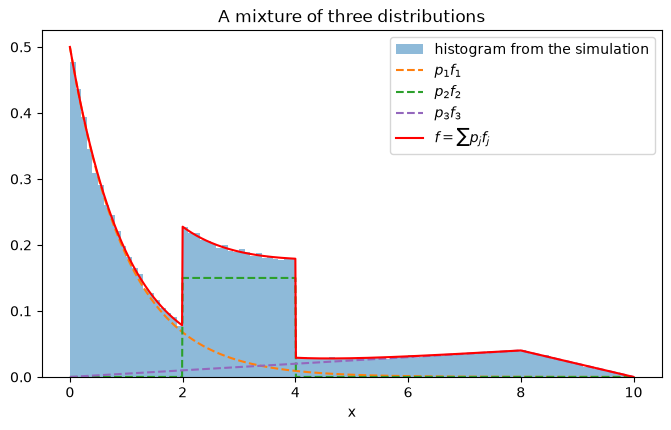

In [3]:
def tri_pdf(a, b, c):
    def f(x):
        if x < a or x > b:
            return 0.0
        if x <= c:
            return 2 * (x - a) / ((b - a) * (c - a))
        return 2 * (b - x) / ((b - a) * (b - c))
    return f


densities = [
    lambda x: math.exp(-x) if x >= 0 else 0.0,
    lambda x: 0.5 if 2 <= x <= 4 else 0.0,
    tri_pdf(0, 10, 8),
]

xs = [mixture() for _ in range(n)]
span, bins = (0, 10), 100
w = (span[1] - span[0]) / bins
grid = [span[0] + (span[1] - span[0]) * i / 1000 for i in range(1001)]

plt.figure(figsize=(8, 4.5))
plt.hist(xs, bins=bins, range=span, weights=[1 / (len(xs) * w)] * len(xs), alpha=0.5, label="histogram from the simulation")
for j, (p, f) in enumerate(zip(weights, densities), start=1):
    plt.plot(grid, [p * f(x) for x in grid], "--", color=["tab:orange", "tab:green", "tab:purple"][j - 1], label=f"$p_{j} f_{j}$")
plt.plot(grid, [sum(p * f(x) for p, f in zip(weights, densities)) for x in grid], "r", label="$f = \\sum p_j f_j$")
plt.xlabel("x")
plt.title("A mixture of three distributions")
plt.legend()
plt.show()

## 2. Ordered samples

We have $\gamma_1, \dots, \gamma_n$ independent uniform on $(0, 1)$ and we want them sorted:
$\gamma_{(1)} \le \gamma_{(2)} \le \dots \le \gamma_{(n)}$. The naive route is to generate them and
**sort** in $O(n \log n)$. But there is a generator that produces the **sorted** numbers directly.

### The derivation

- **The maximum:** $P(\gamma_{(n)} \le x) = P(\text{all } n \text{ numbers} \le x) = x^n$. By the
  inverse transform, $\gamma_{(n)} = V_1^{1/n}$ for $V_1 \sim R(0,1)$.
- **The rest, going down:** given $\gamma_{(k+1)} = u$, the remaining $k$ numbers are (conditionally)
  independent uniform on $(0, u)$. Their maximum is $u \cdot V^{1/k}$ by the previous point, so

$$\gamma_{(k)} = \gamma_{(k+1)}\cdot V_{n-k+1}^{1/k}, \qquad k = n-1,\, n-2,\,\dots,\,1.$$

We need only $n$ uniform numbers and $n$ powers: **time $O(n)$**.

In [4]:
def ordered_uniforms(n):
    '''A sorted sample of n uniform numbers in O(n) time, without sorting.

    The maximum: U_(n) = V^(1/n); then U_(k) = U_(k+1) * V^(1/k) on the way down.
    '''
    out = [0.0] * n
    u = 1.0
    for k in range(n, 0, -1):
        u *= random.random() ** (1.0 / k)
        out[k - 1] = u
    return out


n_ord, runs = 10, 100_000

xs = ordered_uniforms(n_ord)
assert xs == sorted(xs) and 0 <= xs[0] and xs[-1] < 1
print("the output is ordered:", [round(x, 3) for x in xs])

# E U_(k) = k / (n + 1)
for k in (1, 5, 10):
    m, se = estimate(lambda: ordered_uniforms(n_ord)[k - 1], runs)
    check(f"E U_({k}), n = {n_ord}", m, se, k / (n_ord + 1))

the output is ordered: [0.106, 0.119, 0.401, 0.402, 0.596, 0.6, 0.695, 0.706, 0.925, 0.937]
E U_(1), n = 10: 0.09085 +- 0.00026  (exact 0.09091)
E U_(5), n = 10: 0.45419 +- 0.00045  (exact 0.45455)


E U_(10), n = 10: 0.90922 +- 0.00026  (exact 0.90909)


What the recurrence looks like: on the left one run for $n = 12$. Each horizontal bar is the
interval $(0, \gamma_{(k)})$, and the next, **smaller** number is drawn from it; the sortedness
arises by itself. On the right is the distribution of the maximum $\gamma_{(n)}$ (density
$n x^{n-1}$) for $n = 10$.

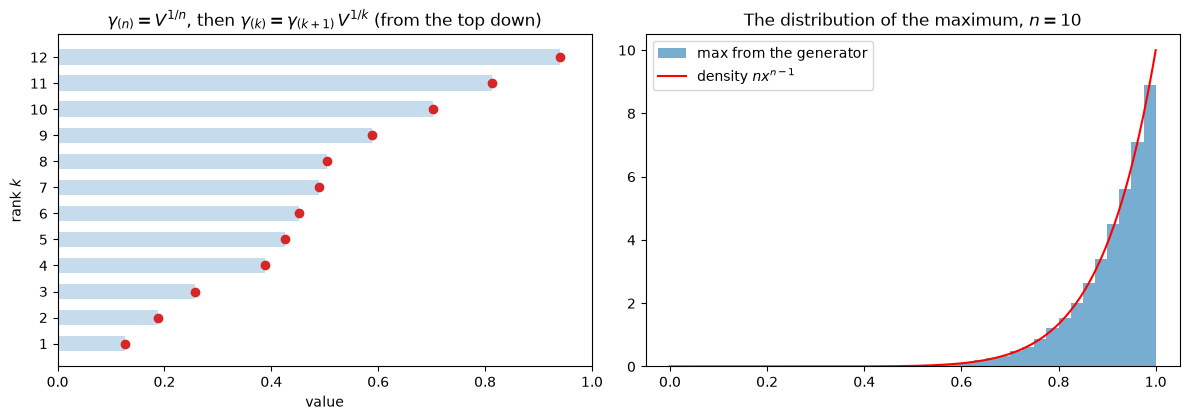

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

n12 = 12
us_ = ordered_uniforms(n12)
ax = axes[0]
for k in range(n12, 0, -1):
    ax.barh(k, us_[k - 1], color="tab:blue", alpha=0.25, height=0.6)
    ax.plot([us_[k - 1]], [k], "o", color="tab:red")
ax.set_xlim(0, 1)
ax.set_yticks(range(1, n12 + 1))
ax.set_ylabel("rank $k$")
ax.set_xlabel("value")
ax.set_title("$\\gamma_{(n)} = V^{1/n}$, then $\\gamma_{(k)} = \\gamma_{(k+1)}\\,V^{1/k}$ (from the top down)")

maxima = [ordered_uniforms(n_ord)[-1] for _ in range(50_000)]
w_ = 1 / 40
axes[1].hist(maxima, bins=40, range=(0, 1), weights=[1 / (len(maxima) * w_)] * len(maxima), alpha=0.6, label="max from the generator")
gr_ = [i / 200 for i in range(201)]
axes[1].plot(gr_, [n_ord * x ** (n_ord - 1) for x in gr_], "r", label="density $n x^{n-1}$")
axes[1].set_title(f"The distribution of the maximum, $n = {n_ord}$")
axes[1].legend()
plt.tight_layout()
plt.show()

### Ordered exponential variables

If $F^{-1}$ is **increasing**, it preserves the order. So we get sorted numbers from any distribution
by transforming sorted uniforms:

In [6]:
def ordered_exponentials(n, lam=1.0):
    # F^-1 is increasing, so it preserves the order of the uniform numbers
    return [-math.log(1.0 - u) / lam for u in ordered_uniforms(n)]


# E[max of n Exp(1)] = H_n = 1 + 1/2 + ... + 1/n  (the harmonic number)
m, se = estimate(lambda: ordered_exponentials(n_ord)[-1], runs)
check("E[max of 10 Exp(1)]", m, se, sum(1 / j for j in range(1, n_ord + 1)))

# E[min of n Exp(1)] = 1/n  (the minimum of n exponentials is Exp(n))
m, se = estimate(lambda: ordered_exponentials(n_ord)[0], runs)
check("E[min of 10 Exp(1)]", m, se, 1 / n_ord)

# in general E X_(k) = 1/n + 1/(n-1) + ... + 1/(n-k+1)  (the Rényi representation)
k = 5
m, se = estimate(lambda: ordered_exponentials(n_ord)[k - 1], runs)
check(f"E X_({k}), n = {n_ord}", m, se, sum(1 / (n_ord - i) for i in range(k)))

E[max of 10 Exp(1)]: 2.93036 +- 0.00396  (exact 2.92897)
E[min of 10 Exp(1)]: 0.10006 +- 0.00032  (exact 0.10000)


E X_(5), n = 10: 0.64708 +- 0.00093  (exact 0.64563)


### Only the largest values out of a huge sample

It is precisely the "top down" recurrence that makes possible something sorting cannot do:
**generating only the $k$ largest numbers out of $n$**, without generating the others. It takes $k$
steps instead of $n$.

A practical example: the largest claim out of $n = 10^8$ insurance events. Naively we would have to
generate and keep a hundred million numbers.

In [7]:
def largest_uniforms(n, k):
    '''The k largest of n uniform numbers, descending, in O(k) time regardless of n.'''
    u = 1.0
    out = []
    for i in range(k):
        u *= random.random() ** (1.0 / (n - i))
        out.append(u)
    return out


N = 10 ** 8
t0 = time.perf_counter()
top = largest_uniforms(N, 3)
print(f"the 3 largest of {N:,} uniform numbers (in {(time.perf_counter() - t0) * 1e6:.0f} us):".replace(",", " "))
print("  ", top)

# The numbers are almost at 1, so we look at N * (1 - U_(N-j)) ~ Gamma(j + 1), with mean (j + 1) * N/(N + 1)
for j in range(3):
    m, se = estimate(lambda: N * (1 - largest_uniforms(N, j + 1)[j]), 100_000)
    check(f"E[N (1 - U_(N-{j}))]", m, se, (j + 1) * N / (N + 1))

the 3 largest of 100 000 000 uniform numbers (in 44 us):
   [0.9999999904507056, 0.9999999856440659, 0.9999999776517007]
E[N (1 - U_(N-0))]: 1.00097 +- 0.00317  (exact 1.00000)
E[N (1 - U_(N-1))]: 2.00200 +- 0.00450  (exact 2.00000)
E[N (1 - U_(N-2))]: 3.00154 +- 0.00548  (exact 3.00000)


The check is on the scale of $N(1 - \gamma)$, because the numbers themselves are only $\sim 10^{-8}$
away from one.

### Speed: is it really faster than sorting?

Asymptotically yes ($O(n)$ against $O(n \log n)$), but in pure Python the constants matter too: the
standard `sorted` is written in C and does the job very fast. Let us measure:

There is also a second route without sorting: if $S_k = E_1 + \dots + E_k$ are the partial sums of
independent $\operatorname{Exp}(1)$ variables, then $\big(S_1/S_{n+1}, \dots, S_n/S_{n+1}\big)$ has
the same distribution as a sorted sample of $n$ uniform numbers. (Behind this lies the connection to
the Poisson process: the points of the process on an interval are, given their number, sorted uniform
numbers.)

In [8]:
def ordered_uniforms_cumsum(n):
    '''The second route: the partial sums of exponential gaps, divided by the last one.'''
    s = list(accumulate(-math.log(1.0 - random.random()) for _ in range(n + 1)))
    last = s[-1]
    return [x / last for x in s[:-1]]


# correctness: E U_(k) = k / (n + 1)
m, se = estimate(lambda: ordered_uniforms_cumsum(n_ord)[4], runs)
check("E U_(5), cumsum, n = 10", m, se, 5 / (n_ord + 1))


def timing(f, repeats=5):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best


print(f"\n{'n':>9s} {'sorted':>10s} {'ordered':>10s} {'cumsum':>10s}   (time in milliseconds, best of 5)")
for nn in (1_000, 100_000):
    t_sort = timing(lambda: sorted(random.random() for _ in range(nn)))
    t_ord = timing(lambda: ordered_uniforms(nn))
    t_cum = timing(lambda: ordered_uniforms_cumsum(nn))
    print(f"{nn:9,d} {t_sort * 1e3:10.2f} {t_ord * 1e3:10.2f} {t_cum * 1e3:10.2f}".replace(",", " "))

E U_(5), cumsum, n = 10: 0.45473 +- 0.00045  (exact 0.45455)

        n     sorted    ordered     cumsum   (time in milliseconds, best of 5)
    1 000       0.12       0.10       0.13


  100 000      17.32      11.01      14.91


On our machine the $O(n)$ method is faster than `sorted` from $n = 1000$ on, and the gap widens with
$n$ (see the table above). The speed-up is not dramatic, because `sorted` is written in C, so the
exact numbers depend on the machine. The **real advantage**, though, is not the speed of sorting but that

- we can generate **only the largest (or smallest) values** in $O(k)$ time,
- we can generate **incrementally** (one at a time, in order), without waiting for the whole sample,
- the same ideas are used for processes where we need **the times of events**.

### An application: claim times in the insurance company

> This is exactly the piece that in **exercise 9** lets us draw the course of the year: the number of
> claims is binomial and their times are a sorted uniform sample.

In the model from exercise 2 the number of claims per year is roughly Poisson with
$\lambda = Np = 18.25$. Given the number $K$, the claim times are **sorted uniform numbers** on
$[0, 1]$ (the year). So we can generate the whole time course of the year without walking through 365
days.

In [9]:
def poisson(lam):
    '''The Poisson distribution by multiplying uniform numbers (exercise 3).'''
    q = math.exp(-lam)
    n = 1
    s = random.random()
    while s > q:
        s *= random.random()
        n += 1
    return n - 1


def claim_times(lam):
    '''The claim times within the year [0, 1]: a Poisson number of sorted uniform numbers.'''
    return ordered_uniforms(poisson(lam))


lam = 365 * 0.05
print("an example of one year:", [round(t, 2) for t in claim_times(lam)][:8], "...")

# E (number of claims in the first half of the year) = lam / 2
m, se = estimate(lambda: float(sum(t < 0.5 for t in claim_times(lam))), 50_000)
check("E number of claims in the 1st half of the year", m, se, lam / 2)

an example of one year: [0.1, 0.19, 0.26, 0.32, 0.33, 0.55, 0.61, 0.63] ...
E number of claims in the 1st half of the year: 9.12444 +- 0.01347  (exact 9.12500)


## 3. An alternative: NumPy

NumPy has sorting (`np.sort`) as well as vectorized operations. Both of the sorting-free methods are
easy to write vectorized. In speed they are close to `np.sort`, since that too is very well
optimized:

In [10]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    N = 1_000_000

    t0 = time.perf_counter()
    a = np.sort(rng.random(N))
    t_sort = time.perf_counter() - t0

    t0 = time.perf_counter()
    s = np.cumsum(rng.exponential(size=N + 1))       # the partial sums of exponential gaps
    b = s[:-1] / s[-1]                               # = the sorted sample
    t_cum = time.perf_counter() - t0

    print(f"np.sort:   {t_sort * 1e3:6.1f} ms,  E U_(k)/(k/(N+1)) for k = N/2: {a[N // 2 - 1] / (N // 2 / (N + 1)):.4f}")
    print(f"cumsum:    {t_cum * 1e3:6.1f} ms,  E U_(k)/(k/(N+1)) for k = N/2: {b[N // 2 - 1] / (N // 2 / (N + 1)):.4f}")
    assert (np.diff(b) >= 0).all()

    # the mixture, vectorized: pick all the components at once and then draw from each
    j = rng.choice(3, size=N, p=[0.5, 0.3, 0.2])
    x = np.where(j == 0, rng.exponential(1.0, N),
        np.where(j == 1, rng.uniform(2, 4, N), rng.triangular(0, 8, 10, N)))
    print(f"mixture, vectorized: E X = {x.mean():.4f}  (exactly 2.6)")
except ModuleNotFoundError:
    print("NumPy is not installed, run:  uv sync")

np.sort:     43.8 ms,  E U_(k)/(k/(N+1)) for k = N/2: 0.9993
cumsum:      10.4 ms,  E U_(k)/(k/(N+1)) for k = N/2: 0.9995


mixture, vectorized: E X = 2.5972  (exactly 2.6)


Watch out for the order of the parameters of NumPy's `triangular(left, mode, right)`: our peak
$c = 8$ is the middle one there.

## Summary

| Concept | What to remember |
|---------|------------------|
| Superposition | $f = \sum p_j f_j$; first draw the component $j$ (discretely), then a value from $f_j$ |
| The mean of a mixture | $\sum p_j\mu_j$ |
| The variance of a mixture | $\sum p_j(\sigma_j^2 + \mu_j^2) - \mu^2$, **not** the weighted average of the variances |
| A sorted sample | $\gamma_{(n)} = V^{1/n}$, $\gamma_{(k)} = \gamma_{(k+1)}V^{1/k}$; $O(n)$ time, no sorting |
| Only the top $k$ of $n$ | $k$ steps are enough, $n$ does not matter |
| A different distribution | a transformation by an increasing $F^{-1}$ preserves the order |
| Speed | the $O(n)$ method is only about 2x faster than `sorted` (which is in C); the real advantage is the top $k$ and incremental generation |

### Try it yourself

1. Build a **mixture of two normal** distributions $N(-2, 1)$ and $N(3, 0.5)$ with weights $0.4$ and
   $0.6$ (use `random.gauss`). Verify the mean and the variance with the formulas from the text and
   draw the histogram. Is the distribution bimodal?
2. **Claims in two classes:** with probability $0.9$ a claim is $\operatorname{Exp}$ with mean
   $1000$, with probability $0.1$ it is $\operatorname{Exp}$ with mean $20\,000$. Compute the mean
   and the variance of the mixture and explain why the mixture looks "heavy-tailed" (what percentage
   of the variance comes from the large claims?).
3. Using `largest_uniforms`, generate the **largest claim** out of $n = 10^6$ insurance events with
   an exponential size $\operatorname{Exp}(1)$ (transform with $-\ln(1 - u)$). Verify the mean
   $H_n \approx \ln n + 0.5772$.